# Cabeza final: de (segmentación + profundidad) a gramos y macronutrientes

**Proyecto IA2 · conteo de calorías por foto**

Este notebook implementa la **cabeza final** del pipeline: la que recibe como entrada los resultados de los dos modelos ya construidos (segmentación con SegFormer-B1 y profundidad entrenada con Nutrition5k) y entrega **gramos por región de comida y los totales de masa, calorías, grasa, carbohidratos y proteína** del plato.

> **Cómo leerlo.** Cada sección tiene primero una explicación (qué se hace y *por qué*) y luego el código. Las celdas marcadas con 🔧 son las únicas que probablemente tengas que tocar en tu PC.

### Resumen de lo que se hizo

1. Se congelan los dos modelos (no se reentrena nada de ellos). Para cada plato de Nutrition5k se calculan **features por región**: qué clase probable es, qué tanta área ocupa y qué tan "alta" (volumen) es la comida según la profundidad.
2. Se entrena una **MLP pequeña tipo *Deep Sets*** que, para cada región, estima los gramos; los totales del plato son la **suma sobre regiones**, que es justo la etiqueta que Nutrition5k sí tiene (masa y macros totales por plato).
3. Se comparan contra baselines (media, regresión lineal) y se hace una ablación **con vs. sin profundidad** para comprobar que la profundidad realmente aporta.
4. Se deja una función de inferencia (`predict_dish`) y se guarda el checkpoint.

### Supuestos (léelos, son importantes)

- **Segmentación:** se usa el SegFormer-B1 de `C:\foodseg_segformer\mit-b1` (formato Hugging Face). Se asume entrada 512×512 con normalización ImageNet; si lo entrenaste con otro tamaño o normalización, cámbialo en la configuración.
- **Profundidad:** el modelo de profundidad se carga con el `depth_inference.py` del notebook de profundidad (sección 2). Mientras tanto el notebook corre con `DEPTH_MODE = "gt"` (la profundidad real `depth_raw.png`), lo que da una **cota superior**. Con `DEPTH_MODE = "model"` usa el DPT-Hybrid fine-tuned vía `depth_inference.py` (el caché se separa por modo).
- **Etiquetas:** solo hay totales por plato (no hay gramos por región). Por eso la cabeza se entrena con la suma.

In [ ]:
from pathlib import Path
import csv, json, time, math, random, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from PIL import Image

# ============ 🔧 RUTAS (ajústalas a tu PC) ============
N5K_ROOT  = Path(r"C:\nutrition5k")                # contiene metadata/ y realsense_overhead/
SEG_DIR   = Path(r"C:\foodseg_segformer\mit-b1")   # config.json + model.safetensors del SegFormer-B1
CACHE_DIR = Path("head_cache")                     # features cacheadas y checkpoint final
CACHE_DIR.mkdir(exist_ok=True)

# ============ 🔧 FUENTE DE PROFUNDIDAD ============
DEPTH_MODE = "model"      # "gt" = depth_raw.png real (cota superior) | "model" = modelo de profundidad entrenado
DEPTH_UNIT = 1e-4      # depth_raw.png -> metros (se verifica justo debajo, al final de la sección 2)
DEPTH_CKPT      = Path(r"C:\nutrition5k\depth_finetune\depth_model_final.pt")   # 🔧 checkpoint guardado por el notebook de profundidad (DPT-Hybrid fine-tuned)
DEPTH_INFER_DIR = DEPTH_CKPT.parent                            # 🔧 carpeta donde está depth_inference.py (cópialo aquí si está en otro lado)

# ============ GEOMETRÍA / REGIONES ============
S         = 128        # lado de la rejilla común donde se calculan las features (SegFormer saca 1/4 de 512 = 128)
SEG_INPUT = 512        # tamaño de entrada del SegFormer
SEG_MEAN  = (0.485, 0.456, 0.406)
SEG_STD   = (0.229, 0.224, 0.225)
MIN_PX    = 24         # una región de menos de 24 px (en la rejilla 128x128) se ignora
R_MAX     = 16         # máximo de regiones por plato (se conservan las más grandes)
BG_ID     = 0          # id de "background" en FoodSeg103

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
TARGETS = ["mass", "kcal", "fat", "carb", "protein"]   # orden de las 5 salidas
UNITS   = ["g", "kcal", "g", "g", "g"]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

set_seed(SEED)
print("device:", DEVICE, "| depth mode:", DEPTH_MODE)

device: cuda | depth mode: model


## 1. Etiquetas: totales por plato desde la metadata

Los CSV de platos tienen 6 columnas de totales (`dish_id, total_calories, total_mass, total_fat, total_carb, total_protein`) y luego bloques de 7 columnas por ingrediente (longitud variable). Para esta cabeza solo necesito los **totales**, así que leo las primeras 6 columnas con el módulo `csv` (pandas se queja con filas de largo variable).

Incluyo una **verificación de cordura**: calorías/masa de un plato real está alrededor de 1–2 kcal/g. Si el orden de columnas fuera otro, esa razón saldría absurda y el `assert` te avisa antes de entrenar con etiquetas cruzadas.

In [ ]:
def load_metadata(meta_dir):
    rows = []
    for fn in ["dish_metadata_cafe1.csv", "dish_metadata_cafe2.csv"]:
        p = meta_dir / fn
        if not p.exists():
            warnings.warn(f"no existe {p}"); continue
        with open(p, newline="", encoding="utf-8") as f:
            for r in csv.reader(f):
                if len(r) < 6: continue
                try:
                    dish, kcal, mass, fat, carb, prot = r[0], *[float(x) for x in r[1:6]]
                except ValueError:
                    continue
                rows.append([dish, mass, kcal, fat, carb, prot])       # reordeno a TARGETS
    return pd.DataFrame(rows, columns=["dish_id"] + TARGETS)

img_root = N5K_ROOT / "realsense_overhead"
df = load_metadata(N5K_ROOT / "metadata")
have = {p.name for p in img_root.iterdir() if (p / "rgb.png").exists()}
df = df[df.dish_id.isin(have) & (df.mass > 5)].drop_duplicates("dish_id").reset_index(drop=True)

ratio = (df.kcal / df.mass).median()
assert 0.3 < ratio < 5, f"kcal/masa mediana = {ratio:.2f}: revisa el orden de columnas del CSV"
print(f"{len(df)} platos con imagen y metadata | kcal/g mediana = {ratio:.2f}")
df.describe().loc[["mean", "std", "min", "max"]].round(1)

3485 platos con imagen y metadata | kcal/g mediana = 1.05


,mass,kcal,fat,carb,protein
mean,211.7,238.7,11.9,18.1,16.9
std,158.6,221.5,13.5,21.4,19.9
min,6.0,0.0,0.0,0.0,0.0
max,3051.0,3943.3,106.3,844.6,147.5


## 2. Los dos modelos como "adaptadores" (congelados)

La cabeza **no reentrena** ninguno de los dos modelos; solo consume sus salidas. Por eso los envuelvo en funciones con un contrato claro:

| Adaptador | Entrada | Salida |
|---|---|---|
| `SegAdapter.probs` | RGB uint8 `(B,512,512,3)` | probabilidades `(B, C, 128, 128)` (softmax de los logits) |
| profundidad | RGB o `depth_raw.png` | profundidad en **metros** `(B,128,128)` (distancia cámara → superficie) |

**Por qué probabilidades y no solo la clase ganadora:** el SegFormer-B1 tiene mIoU ≈ 0.27, o sea que se equivoca bastante de clase. Si le paso a la cabeza solo el `argmax`, pierde la incertidumbre ("esto es 40 % arroz, 30 % lentejas"). Con las probabilidades promedio de la región la cabeza puede aprender a ser prudente.

### Profundidad: dos modos
- `DEPTH_MODE = "gt"`: usa `depth_raw.png` (profundidad real). Sirve para desarrollar y da una **cota superior**.
- `DEPTH_MODE = "model"`: usa el **DPT-Hybrid fine-tuned** del notebook de profundidad, vía su `depth_inference.py`. Su salida ya está en **metros** (`prior · exp(salida)`), que es lo que asume todo lo de abajo, así que no hace falta convertir nada. Requiere ajustar `DEPTH_CKPT` en la configuración. Es la cifra que cuenta para la app final, porque ahí no habrá `depth_raw.png`.

In [ ]:
# ---------- Segmentación (SegFormer-B1 congelado) ----------
class SegAdapter:
    def __init__(self, seg_dir, device):
        from transformers import SegformerForSemanticSegmentation
        self.device = device
        self.model = SegformerForSemanticSegmentation.from_pretrained(str(seg_dir)).to(device).eval()
        for p in self.model.parameters(): p.requires_grad_(False)
        self.C = self.model.config.num_labels
        self.id2label = {int(k): v for k, v in self.model.config.id2label.items()}
        self.mean = torch.tensor(SEG_MEAN, device=device).view(1, 3, 1, 1)
        self.std  = torch.tensor(SEG_STD,  device=device).view(1, 3, 1, 1)

    @torch.no_grad()
    def probs(self, rgb_u8):
        """rgb_u8: np.uint8 (B,SEG_INPUT,SEG_INPUT,3) -> torch (B,C,S,S) con softmax sobre clases."""
        x = torch.from_numpy(rgb_u8).to(self.device).permute(0, 3, 1, 2).float() / 255.0
        x = (x - self.mean) / self.std
        logits = self.model(pixel_values=x).logits                     # (B,C,128,128) a 1/4 de resolución
        if logits.shape[-1] != S:
            logits = F.interpolate(logits, size=(S, S), mode="bilinear", align_corners=False)
        return logits.softmax(1)

# ---------- Profundidad ----------
def load_depth_raw(path):
    return np.array(Image.open(path)).astype(np.float32)          # uint16 -> float32

DEPTH_MAX_M = 0.6      # todo lo más lejos que esto (o saturado en 65535) es lectura inválida, no mesa

def depth_from_gt(dish_dir):
    """depth_raw.png -> metros, inválidos (0 y 65535) rellenados con el vecino válido más cercano, reducido a SxS."""
    raw = load_depth_raw(dish_dir / "depth_raw.png")
    valid = (raw > 0) & (raw < 65535) & (raw * DEPTH_UNIT < DEPTH_MAX_M)
    d = raw * DEPTH_UNIT
    if valid.any() and not valid.all():
        idx = ndi.distance_transform_edt(~valid, return_distances=False, return_indices=True)
        d = d[tuple(idx)]                                        # cada hueco toma el valor del píxel válido más cercano
    elif not valid.any():
        d = np.full_like(d, 0.36)
    t = torch.from_numpy(d.astype(np.float32))[None, None]
    return F.interpolate(t, size=(S, S), mode="area")[0, 0].numpy()

def load_depth_model():
    """
    Carga el DPT-Hybrid fine-tuned en Nutrition5k usando depth_inference.py (el que guarda el notebook de profundidad).
    Devuelve (model, prior). Necesita los pesos base 'Intel/dpt-hybrid-midas' en la caché de Hugging Face
    (la primera vez se descargan de internet); luego load_state_dict los reemplaza por los fine-tuned.
    """
    import sys
    if str(DEPTH_INFER_DIR) not in sys.path:
        sys.path.insert(0, str(DEPTH_INFER_DIR))
    from depth_inference import load_depth_model as _load
    return _load(str(DEPTH_CKPT), DEVICE)

@torch.no_grad()
def depth_from_model(depth_model, dish_dirs):
    """
    Por plato: foto RGB ORIGINAL (640x480) -> predict_depth_m (profundidad en METROS = prior * exp(salida),
    con ventanas 384x384 solapadas porque la imagen no es cuadrada) -> reducida a SxS.
    Se usa la foto original (no la de 512x512 del segmentador) para no deformar la proporción que vio el modelo al entrenar.
    """
    from depth_inference import predict_depth_m
    model, prior = depth_model
    out = []
    for d in dish_dirs:
        dm = predict_depth_m(model, prior, Image.open(d / "rgb.png"))          # np.float32 (H,W) en metros
        t = torch.from_numpy(dm.astype(np.float32))[None, None]
        out.append(F.interpolate(t, size=(S, S), mode="area")[0, 0].numpy())
    return np.stack(out)

def get_depth_batch(dish_dirs, rgb_u8, depth_model=None):
    if DEPTH_MODE == "gt":
        return np.stack([depth_from_gt(d) for d in dish_dirs])
    return depth_from_model(depth_model, dish_dirs)

### Comprobación de unidades de la profundidad (haz esto una vez)

Todo el cálculo de "altura de la comida" depende de que `depth_raw.png` esté en las unidades que creo (`DEPTH_UNIT = 1e-4` → décimas de milímetro). La cámara de Nutrition5k está montada unos 35 cm sobre la mesa, así que la profundidad mediana del plato debería salir en el orden de **0.3–0.4 m**. Si ves algo muy distinto (p. ej. 3.6 o 0.0036), ajusta `DEPTH_UNIT`. También verás que una parte de los píxeles son **inválidos**: `0` (sin lectura) y `65535` (valor saturado de `uint16`, no son 6.5 m). `depth_from_gt` los descarta y rellena cada uno con el valor válido más cercano, para no sesgar la altura de la comida.

In [ ]:
d0 = load_depth_raw(img_root / df.dish_id[0] / "depth_raw.png")
inval = (d0 == 0) | (d0 >= 65535)
v = d0[~inval]
print("forma:", d0.shape, "| ceros:", f"{(d0 == 0).mean() * 100:.1f}%", "| saturados (65535):", f"{(d0 >= 65535).mean() * 100:.1f}%")
print("valores crudos válidos: min/mediana/max =", v.min(), np.median(v), v.max())
print(f"mediana en metros con DEPTH_UNIT={DEPTH_UNIT}: {np.median(v) * DEPTH_UNIT:.3f} m  (esperado ~0.3-0.4)")

forma: (480, 640) | ceros: 20.5% | saturados (65535): 0.0%
valores crudos válidos: min/mediana/max = 2796.0 3511.0 40768.0
mediana en metros con DEPTH_UNIT=0.0001: 0.351 m  (esperado ~0.3-0.4)


## 3. De los mapas de salida a *features por región*

Aquí está la idea central. Un plato no se le entrega a la MLP como una imagen, sino como un **conjunto de regiones** (como definiste: componentes conectados de la clase predicha, sin el fondo). Para cada región calculo:

- **Distribución de clase** `P[r]`: promedio de las probabilidades del SegFormer dentro de la región (vector de C=104 números que suma 1).
- **Geometría** `G[r]` (5 números): fracción de área, y estadísticas de **altura** (media, desviación, percentil 90) más un **proxy de volumen** (suma de alturas / píxeles totales).
- **Globales del plato** `GL` (5 números): distancia cámara-mesa, fracción de imagen que es comida, nº de regiones, altura media y volumen total de la comida.

**¿Qué es "altura"?** Desde arriba, la cámara ve la superficie. La mesa/plato está a una profundidad `plane` y la comida, al sobresalir, está *más cerca* de la cámara. Entonces `altura = plane − profundidad` (recortada a ≥ 0). `plane` se estima como la **mediana de la profundidad de los píxeles de fondo** (clase 0 del SegFormer), y si hay muy poco fondo visible se usa el percentil 95 de toda la imagen.

**¿Por qué no calculo el volumen en cm³ reales?** Para eso necesito los intrínsecos de la cámara (tamaño real de un píxel a cada profundidad). En vez de fijar una calibración que podría estar mal, dejo el volumen en unidades relativas y la MLP **aprende la escala** (volumen relativo → gramos) con los datos. Si más adelante quieren convertir a cm³ reales, solo se añade un factor.

In [ ]:
GEOM_NAMES = ["area_frac", "h_mean_cm", "h_std_cm", "h_p90_cm", "vol"]
GLOB_NAMES = ["plane_cm", "food_frac", "n_regions", "h_mean_all_cm", "vol_total"]
N_GEOM, N_GLOB = len(GEOM_NAMES), len(GLOB_NAMES)

def build_regions(probs, depth_m, min_px=MIN_PX, r_max=R_MAX, bg_id=BG_ID, return_extra=False):
    """
    probs   : np.float32 (C,S,S) softmax del segmentador
    depth_m : np.float32 (S,S)   metros (cámara -> superficie)
    Devuelve P (r_max,C), G (r_max,N_GEOM), M (r_max,) bool, GL (N_GLOB,)  [padding con ceros]
    """
    C, H, W = probs.shape
    tot = float(H * W)
    pred = probs.argmax(0)
    bg = pred == bg_id

    plane = np.median(depth_m[bg]) if bg.sum() >= 200 else np.percentile(depth_m, 95)
    height_cm = np.clip(plane - depth_m, 0, None) * 100.0

    cands = []
    for c in np.unique(pred):
        if c == bg_id: continue
        lab, n = ndi.label(pred == c)                       # componentes conectados de la clase c
        if n == 0: continue
        sizes = np.bincount(lab.ravel())[1:]
        for i, sz in enumerate(sizes, start=1):
            if sz >= min_px: cands.append((int(sz), lab == i))
    cands.sort(key=lambda t: -t[0])
    cands = cands[:r_max]

    P = np.zeros((r_max, C), np.float32)
    G = np.zeros((r_max, N_GEOM), np.float32)
    M = np.zeros(r_max, bool)
    masks = []
    for r, (sz, m) in enumerate(cands):
        h = height_cm[m]
        P[r] = probs[:, m].mean(1)
        G[r] = [sz / tot, h.mean(), h.std(), np.percentile(h, 90), h.sum() / tot]
        M[r] = True
        masks.append(m)

    food = ~bg
    GL = np.array([plane * 100.0, food.mean(), len(cands) / r_max,
                   height_cm[food].mean() if food.any() else 0.0,
                   height_cm[food].sum() / tot], np.float32)
    if return_extra:
        return P, G, M, GL, dict(masks=masks, height_cm=height_cm, plane=plane, pred=pred)
    return P, G, M, GL

### Extracción para todo el dataset (se hace una sola vez y se guarda en disco)

Como los dos modelos están congelados, sus salidas **no cambian entre épocas**, así que las calculo una vez y las cacheo en `head_cache/feats_<modo>.npz`. Eso hace que entrenar la cabeza tome segundos en lugar de horas, y permite probar muchas ablaciones.

El parámetro `seg_post` es el **gancho para tu cabeza de clasificación por región**: si quieres que la clase de cada región venga de ella y no del voto del SegFormer, pásale una función `seg_post(probs[C,S,S], rgb[512,512,3]) -> probs[C,S,S]` que devuelva, para cada región, la distribución de la cabeza de clasificación. Por defecto no hace nada.

In [ ]:
def extract_cache(df, seg, depth_model=None, bs=16, seg_post=None, force=False):
    out_path = CACHE_DIR / f"feats_{DEPTH_MODE}.npz"
    if out_path.exists() and not force:
        print("cargando caché:", out_path)
        z = np.load(out_path, allow_pickle=False)
        return {k: z[k] for k in z.files}

    ids = df.dish_id.tolist()
    Ps, Gs, Ms, GLs = [], [], [], []
    t0 = time.time()
    for i in range(0, len(ids), bs):
        chunk = ids[i:i + bs]
        dirs = [img_root / d for d in chunk]
        rgb = np.stack([np.array(Image.open(d / "rgb.png").convert("RGB").resize((SEG_INPUT, SEG_INPUT), Image.BILINEAR))
                        for d in dirs])
        probs = seg.probs(rgb).cpu().numpy()                      # (B,C,S,S)
        depth = get_depth_batch(dirs, rgb, depth_model)           # (B,S,S) en metros
        for b in range(len(chunk)):
            pr = probs[b] if seg_post is None else seg_post(probs[b], rgb[b])
            P, G, M, GL = build_regions(pr, depth[b])
            Ps.append(P); Gs.append(G); Ms.append(M); GLs.append(GL)
        if (i // bs) % 20 == 0:
            print(f"  {i + len(chunk)}/{len(ids)}  ({time.time() - t0:.0f}s)")
    cache = dict(P=np.stack(Ps).astype(np.float16), G=np.stack(Gs), M=np.stack(Ms), GL=np.stack(GLs),
                 Y=df[TARGETS].values.astype(np.float32), ids=np.array(ids))
    np.savez_compressed(out_path, **cache)
    print("guardado:", out_path, "|", f"{time.time() - t0:.0f}s")
    return cache

## 4. La cabeza: una MLP tipo *Deep Sets* con "tabla nutricional aprendida"

### El problema de supervisión
Nutrition5k solo da etiquetas **por plato** (masa y macros totales), no por región. La solución es diseñar la red para que **la predicción del plato sea la suma de las predicciones de sus regiones**; así la etiqueta del plato sí supervisa a cada región indirectamente.

### Arquitectura (para cada región `r` de un plato)

```
probs_r ──► Linear (C→32) ──► e_r  ┐
geometría_r (5) ─────────────────────┼─► MLP(2 capas) ─► softplus ─► gramos_r  (≥ 0)
globales del plato (5) ──────────────┘

densidad_r = (probs_r @ exp(T)) · prior       T = tabla aprendida (C × 4): kcal/g, grasa/g, carb/g, prot/g
```

Totales del plato:

- `masa = Σ_r gramos_r`
- `kcal, grasa, carb, prot = Σ_r gramos_r · densidad_r`

### Por qué así (y no una MLP que escupa directo los 5 totales)
- **Respeta la física:** más comida → más masa; no puede predecir calorías sin gramos que las expliquen.
- **Es interpretable y se conecta con tu plan original:** la salida por región son *gramos*, que es exactamente lo que necesita la tabla nutricional (base de datos propia o API). Cuando tengan esa tabla, se reemplaza la densidad aprendida por la real y la cabeza solo aporta los gramos.
- **Invariante al orden y al número de regiones** (la suma no depende de cómo las ordenes), que es lo que se quiere para "un plato = un conjunto de porciones".
- **`prior`:** la densidad parte de la razón media de todo el dataset (p. ej. ~1.5 kcal/g) y la tabla `T` solo aprende **desviaciones multiplicativas** (`exp(T)`, con `T = 0` al inicio). Una regularización L2 sobre `T` evita que se invente densidades absurdas para clases que casi no aparecen.
- **Probabilidades blandas:** tanto el embedding como la densidad usan `probs_r` completo (no el `argmax`), así que un error de clase del SegFormer se "promedia" en vez de contaminar todo.

### Pérdida
L1 sobre los 5 totales, cada uno **dividido por su media de entrenamiento** (así masa y calorías pesan parecido y la pérdida equivale a un %MAE, que es la métrica natural en Nutrition5k).

In [ ]:
class NutritionHead(nn.Module):
    def __init__(self, n_classes, prior, hidden=128, emb=32, drop=0.1, use_depth=True, mass_scale=100.0):
        super().__init__()
        self.cls_emb = nn.Linear(n_classes, emb, bias=False)           # embedding "blando": probs @ E
        self.enc = nn.Sequential(
            nn.Linear(emb + N_GEOM + N_GLOB, hidden), nn.GELU(), nn.Dropout(drop),
            nn.Linear(hidden, hidden), nn.GELU(),
            nn.Linear(hidden, 1))
        self.log_dens = nn.Parameter(torch.zeros(n_classes, 4))        # tabla de densidades (log-escala, parte en 0)
        self.register_buffer("prior", torch.as_tensor(prior, dtype=torch.float32))   # (4,) por gramo: kcal, fat, carb, prot
        self.mass_scale = mass_scale
        # ablación: sin profundidad solo se conservan las features que NO dependen de ella
        gkeep = torch.tensor([1, 0, 0, 0, 0], dtype=torch.float32) if not use_depth else torch.ones(N_GEOM)
        glkeep = torch.tensor([0, 1, 1, 0, 0], dtype=torch.float32) if not use_depth else torch.ones(N_GLOB)
        self.register_buffer("gkeep", gkeep); self.register_buffer("glkeep", glkeep)

    def forward(self, P, G, GL, M):
        """P (B,R,C) · G (B,R,5) · GL (B,5) · M (B,R) float 0/1  -> dict con totales (B,5) y gramos/densidad por región."""
        e = self.cls_emb(P)
        g = GL[:, None, :].expand(-1, P.size(1), -1) * self.glkeep
        h = torch.cat([e, G * self.gkeep, g], dim=-1)
        grams = F.softplus(self.enc(h).squeeze(-1)) * self.mass_scale * M          # (B,R)
        dens = (P @ torch.exp(self.log_dens)) * self.prior                          # (B,R,4) por gramo
        macros = (grams[..., None] * dens).sum(1)                                   # (B,4)
        total = torch.cat([grams.sum(1, keepdim=True), macros], dim=1)              # (B,5) = [masa, kcal, grasa, carb, prot]
        return dict(total=total, grams=grams, dens=dens)

## 5. Entrenamiento

- **Split:** 80/10/10 aleatorio por plato con semilla fija. *(Nutrition5k trae splits oficiales, pero en tu descarga solo están `realsense_overhead` y `metadata`; si los consigues, es mejor usarlos para comparar con el paper.)*
- **Normalización:** media y desviación de las features calculadas **solo con el set de entrenamiento** (si las calculara con todo el dataset, estaría filtrando información del test).
- **Selección de modelo:** early stopping por %MAE medio en validación; el test solo se mira al final.
- Como las features ya están en memoria (cacheadas), no necesito `DataLoader`: cada época son unas decenas de pasos.

In [ ]:
CFG = dict(hidden=128, emb=32, drop=0.1, lr=2e-3, wd=1e-3, bs=64, epochs=150, patience=25, dens_reg=1e-2)

def make_splits(n, seed=SEED, fr=(0.8, 0.1)):
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    a, b = int(n * fr[0]), int(n * (fr[0] + fr[1]))
    return dict(train=perm[:a], val=perm[a:b], test=perm[b:])

def fit_norm(cache, tr_idx):
    G, M = cache["G"][tr_idx], cache["M"][tr_idx]
    gv = G[M]                                                    # solo regiones válidas
    GL = cache["GL"][tr_idx]
    Y = cache["Y"][tr_idx]
    prior = (Y[:, 1:].sum(0) / Y[:, 0].sum()).astype(np.float32)   # kcal/g, fat/g, carb/g, prot/g (razón global)
    return dict(g_mean=gv.mean(0), g_std=np.maximum(gv.std(0), 1e-6),
                gl_mean=GL.mean(0), gl_std=np.maximum(GL.std(0), 1e-6),
                y_scale=Y.mean(0).astype(np.float32), prior=prior)

def apply_norm(P, G, M, GL, norm):
    Gn = (G - norm["g_mean"]) / norm["g_std"] * M[..., None]
    GLn = (GL - norm["gl_mean"]) / norm["gl_std"]
    return P.astype(np.float32), Gn.astype(np.float32), M.astype(np.float32), GLn.astype(np.float32)

def to_tensors(cache, idx, norm, device=DEVICE):
    P, G, M, GL = apply_norm(cache["P"][idx], cache["G"][idx], cache["M"][idx], cache["GL"][idx], norm)
    t = lambda a: torch.from_numpy(a).to(device)
    return dict(P=t(P), G=t(G), M=t(M), GL=t(GL), Y=t(cache["Y"][idx]))

def metrics(y, yhat):
    mae = np.abs(y - yhat).mean(0)
    return dict(mae=mae, pct=mae / y.mean(0) * 100.0)

@torch.no_grad()
def predict_tensors(model, T):
    model.eval()
    out = model(T["P"], T["G"], T["GL"], T["M"])
    return out["total"].cpu().numpy()

def train_head(Ttr, Tva, norm, n_classes, cfg=CFG, use_depth=True, seed=SEED, verbose=True):
    set_seed(seed)
    model = NutritionHead(n_classes, norm["prior"], cfg["hidden"], cfg["emb"], cfg["drop"], use_depth).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    ys = torch.as_tensor(norm["y_scale"], device=DEVICE)
    n = Ttr["P"].shape[0]
    best, best_state, bad = 1e9, None, 0
    for ep in range(cfg["epochs"]):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for b in range(0, n, cfg["bs"]):
            ix = perm[b:b + cfg["bs"]]
            out = model(Ttr["P"][ix], Ttr["G"][ix], Ttr["GL"][ix], Ttr["M"][ix])
            loss = F.l1_loss(out["total"] / ys, Ttr["Y"][ix] / ys) + cfg["dens_reg"] * (model.log_dens ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        val = metrics(Tva["Y"].cpu().numpy(), predict_tensors(model, Tva))["pct"].mean()
        if val < best - 1e-3:
            best, bad = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose and ep % 10 == 0:
            print(f"ep {ep:3d} | loss {loss.item():.4f} | val %MAE medio {val:.2f} (mejor {best:.2f})")
        if bad >= cfg["patience"]:
            if verbose: print(f"early stopping en ep {ep}")
            break
    model.load_state_dict(best_state)
    return model, best

### Baselines (para saber si la cabeza vale la pena)

Un número de %MAE solo no dice nada; hay que compararlo con algo trivial:

1. **Media:** predecir siempre el promedio del set de entrenamiento.
2. **Ridge sobre agregados del plato:** regresión lineal con área total de comida, volumen total, altura media, distancia a la mesa y nº de regiones. Si la cabeza no supera claramente a esto, la complejidad extra no se justifica.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def dish_aggregates(cache, idx):
    G, M, GL = cache["G"][idx], cache["M"][idx], cache["GL"][idx]
    area = (G[..., 0] * M).sum(1); vol = (G[..., 4] * M).sum(1)
    return np.c_[area, vol, GL[:, 0], GL[:, 3], GL[:, 2]]

def run_baselines(cache, sp):
    Ytr, Yte = cache["Y"][sp["train"]], cache["Y"][sp["test"]]
    res = {}
    res["Media"] = metrics(Yte, np.tile(Ytr.mean(0), (len(Yte), 1)))
    rg = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(dish_aggregates(cache, sp["train"]), Ytr)
    res["Ridge (agregados)"] = metrics(Yte, rg.predict(dish_aggregates(cache, sp["test"])))
    return res

## 6. Prueba rápida con datos sintéticos (recomendada antes de lo pesado)

Antes de extraer features de 3490 platos, esta celda genera un dataset **falso pero con estructura conocida** (gramos = f(volumen, clase), macros = gramos × densidad por clase) y entrena la cabeza. Sirve para confirmar en 1–2 minutos que el entorno, la GPU y el código funcionan: **la cabeza debe superar por mucho a la media**. Si aquí falla, el problema es de código/entorno, no de los datos reales.

In [ ]:
def make_synthetic_cache(n=900, C=104, seed=0):
    rng = np.random.default_rng(seed)
    dens = np.c_[rng.uniform(0.4, 3.5, C), rng.uniform(0.0, 0.3, C), rng.uniform(0.0, 0.4, C), rng.uniform(0.0, 0.3, C)]
    fac = rng.uniform(0.6, 1.4, C)
    P = np.zeros((n, R_MAX, C), np.float32); G = np.zeros((n, R_MAX, N_GEOM), np.float32)
    M = np.zeros((n, R_MAX), bool); GL = np.zeros((n, N_GLOB), np.float32); Y = np.zeros((n, 5), np.float32)
    for i in range(n):
        k = rng.integers(1, 7); area = rng.dirichlet(np.ones(k)) * rng.uniform(0.15, 0.6)
        h = rng.uniform(0.5, 4.0, k)
        tot_g = 0; tot_m = np.zeros(4)
        for r in range(k):
            c = rng.integers(1, C)
            p = rng.dirichlet(np.ones(C) * 0.05); p = 0.7 * np.eye(C)[c] + 0.3 * p
            P[i, r] = p; M[i, r] = True
            G[i, r] = [area[r], h[r], 0.3 * h[r], 1.2 * h[r], area[r] * h[r]]
            g = 900.0 * area[r] * h[r] * fac[c]
            tot_g += g; tot_m += g * dens[c]
        GL[i] = [36.0, area.sum(), k / R_MAX, (area * h).sum() / area.sum(), (area * h).sum()]
        Y[i] = [tot_g, *tot_m]
    return dict(P=P.astype(np.float16), G=G, M=M, GL=GL, Y=Y, ids=np.arange(n).astype(str))

def smoke_test(verbose=False):
    cache = make_synthetic_cache()
    sp = make_splits(len(cache["Y"]))
    norm = fit_norm(cache, sp["train"])
    T = {k: to_tensors(cache, sp[k], norm) for k in sp}
    cfg = dict(CFG, epochs=60, patience=15)
    model, best = train_head(T["train"], T["val"], norm, cache["P"].shape[-1], cfg, use_depth=True, verbose=verbose)
    head = metrics(cache["Y"][sp["test"]], predict_tensors(model, T["test"]))["pct"]
    base = run_baselines(cache, sp)
    print("%MAE test  [masa, kcal, grasa, carb, prot]")
    print("  Media :", np.round(base["Media"]["pct"], 1))
    print("  Ridge :", np.round(base["Ridge (agregados)"]["pct"], 1))
    print("  Cabeza:", np.round(head, 1))
    return head, base

head_s, base_s = smoke_test()

%MAE test  [masa, kcal, grasa, carb, prot]
  Media : [42.2 45.6 54.9 51.4 54.1]
  Ridge : [11.3 27.6 38.9 34.5 34.4]
  Cabeza: [ 8.9 11.5 20.8 18.  18.3]


## 7. Corrida con los datos reales

Se cargan los modelos, se extraen (o se leen del caché) las features y se parte el dataset. La primera vez la extracción recorre los 3490 platos; con la RTX 5060 debería tomar pocos minutos (la parte más lenta es el cálculo de componentes conectados en CPU).

Al terminar, `C` debería ser **104** (103 clases de FoodSeg103 + fondo). Si no, el `BG_ID` o el checkpoint no son los que creo.

In [ ]:
seg = SegAdapter(SEG_DIR, DEVICE)
C = seg.C
print("clases del segmentador:", C, "| fondo:", seg.id2label.get(BG_ID))

depth_model = load_depth_model() if DEPTH_MODE == "model" else None      # (model, prior) del DPT
cache = extract_cache(df, seg, depth_model)               # <- seg_post=tu_cabeza_de_clasificacion si quieres usarla

sp = make_splits(len(cache["Y"]))
norm = fit_norm(cache, sp["train"])
T = {k: to_tensors(cache, sp[k], norm) for k in sp}
n_reg = cache["M"].sum(1)
print({k: len(v) for k, v in sp.items()}, "| regiones por plato: media %.1f, máx %d, platos sin regiones: %d"
      % (n_reg.mean(), n_reg.max(), (n_reg == 0).sum()))
print("prior de densidad (kcal/g, grasa/g, carb/g, prot/g):", np.round(norm["prior"], 3))

Loading weights: 100%|██████████| 208/208 [00:00<00:00, 3599.27it/s]

clases del segmentador: 104 | fondo: background



Loading weights: 100%|██████████| 414/414 [00:00<00:00, 34493.59it/s]


  16/3485  (5s)
  336/3485  (87s)
  656/3485  (170s)
  976/3485  (254s)
  1296/3485  (338s)
  1616/3485  (421s)
  1936/3485  (505s)
  2256/3485  (588s)
  2576/3485  (672s)
  2896/3485  (756s)
  3216/3485  (840s)
guardado: head_cache\feats_model.npz | 911s
{'train': 2788, 'val': 348, 'test': 349} | regiones por plato: media 6.7, máx 16, platos sin regiones: 3
prior de densidad (kcal/g, grasa/g, carb/g, prot/g): [1.131 0.057 0.085 0.08 ]


### Experimentos: ¿aporta la profundidad?

Entreno **dos variantes con 3 semillas cada una** (para no sacar conclusiones de una sola corrida con suerte):

- **Sin profundidad:** la cabeza solo ve clase, área de cada región, fracción de comida y nº de regiones.
- **Con profundidad:** además ve las alturas y el volumen.

Si "con profundidad" no mejora claramente la masa respecto a "sin profundidad", algo está mal en la profundidad o en las unidades (por eso es la ablación más importante de este notebook).

In [ ]:
SEEDS = [0, 1, 2]

def run_experiment(name, use_depth):
    runs = []
    for s in SEEDS:
        model, best = train_head(T["train"], T["val"], norm, C, CFG, use_depth=use_depth, seed=s, verbose=False)
        te = metrics(cache["Y"][sp["test"]], predict_tensors(model, T["test"]))
        runs.append((best, model, te))
        print(f"  {name} | semilla {s}: val {best:.2f} | test {te['pct'].mean():.2f}")
    return runs

t0 = time.time()
runs_nod = run_experiment("sin profundidad", use_depth=False)
runs_d   = run_experiment("con profundidad", use_depth=True)
print(f"{time.time() - t0:.0f}s")

  sin profundidad | semilla 0: val 43.23 | test 38.29
  sin profundidad | semilla 1: val 43.67 | test 38.39
  sin profundidad | semilla 2: val 43.24 | test 38.27
  con profundidad | semilla 0: val 42.46 | test 37.82
  con profundidad | semilla 1: val 42.64 | test 37.97
  con profundidad | semilla 2: val 42.84 | test 37.61
74s


## 8. Resultados

Tabla de **%MAE en test** (error absoluto medio relativo a la media del target; menor es mejor). Para las cabezas se muestra el promedio de las 3 semillas ± desviación. El modelo que se guardará es la mejor semilla **según validación** (no según test).

In [ ]:
def fmt(runs):
    pct = np.stack([r[2]["pct"] for r in runs])
    return pct.mean(0), pct.std(0)

rows = {}
for k, v in run_baselines(cache, sp).items():
    rows[k] = (v["pct"], np.zeros(5))
rows["Cabeza SIN profundidad"] = fmt(runs_nod)
rows["Cabeza CON profundidad"] = fmt(runs_d)

tab = pd.DataFrame({k: [f"{m:.1f} ± {s:.1f}" if s > 0 else f"{m:.1f}" for m, s in zip(*v)] for k, v in rows.items()},
                   index=TARGETS).T
tab["promedio"] = [f"{np.mean(v[0]):.1f}" for v in rows.values()]
display(tab) if "display" in globals() else print(tab)

# MAE absoluto del mejor modelo (por validación)
best_run = min(runs_d, key=lambda r: r[0])
best_model = best_run[1]
mae_abs = best_run[2]["mae"]
print("\nMejor modelo (por val) — MAE absoluto en test:",
      ", ".join(f"{t} {m:.1f} {u}" for t, m, u in zip(TARGETS, mae_abs, UNITS)))

                              mass        kcal         fat        carb  \
Media                         54.5        68.9        83.7        68.9   
Ridge (agregados)             31.2        48.0        68.8        60.6   
Cabeza SIN profundidad  27.6 ± 0.1  30.9 ± 0.2  48.6 ± 0.1  41.0 ± 0.2   
Cabeza CON profundidad  28.4 ± 0.4  30.2 ± 0.0  47.3 ± 0.1  40.5 ± 0.5   

                           protein promedio  
Media                         89.1     73.0  
Ridge (agregados)             63.5     54.4  
Cabeza SIN profundidad  43.4 ± 0.1     38.3  
Cabeza CON profundidad  42.6 ± 0.2     37.8  

Mejor modelo (por val) — MAE absoluto en test: mass 60.5 g, kcal 72.1 kcal, fat 5.7 g, carb 7.2 g, protein 7.1 g


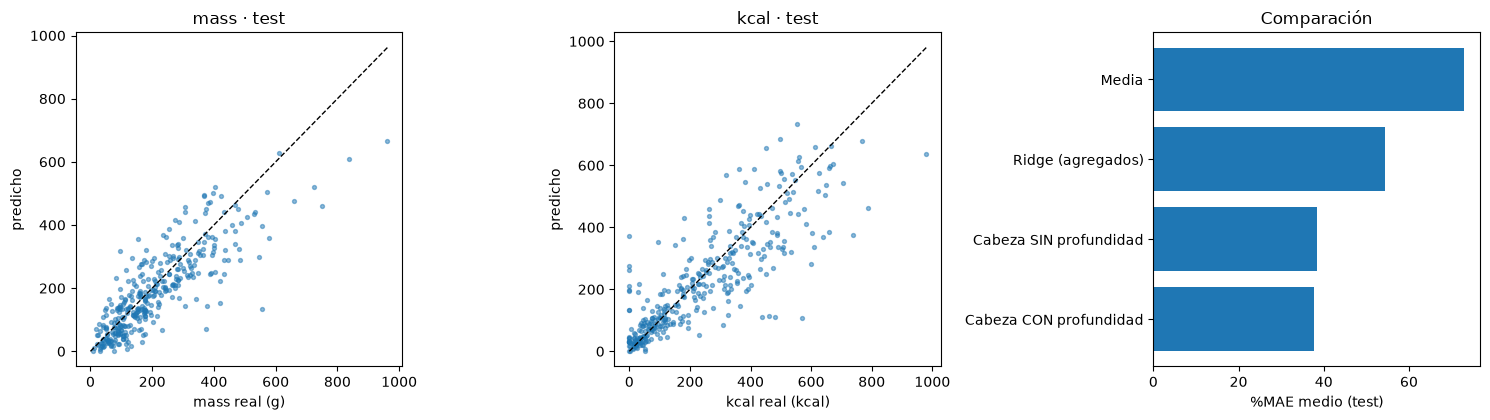

In [ ]:
yhat = predict_tensors(best_model, T["test"]); ytrue = cache["Y"][sp["test"]]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, k in zip(ax[:2], [0, 1]):
    a.scatter(ytrue[:, k], yhat[:, k], s=8, alpha=0.5)
    lim = max(ytrue[:, k].max(), yhat[:, k].max()); a.plot([0, lim], [0, lim], "k--", lw=1)
    a.set_xlabel(f"{TARGETS[k]} real ({UNITS[k]})"); a.set_ylabel("predicho"); a.set_title(f"{TARGETS[k]} · test")
names = list(rows.keys()); means = [np.mean(rows[n][0]) for n in names]
ax[2].barh(names, means); ax[2].set_xlabel("%MAE medio (test)"); ax[2].set_title("Comparación"); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

### Mirar qué aprendió la "tabla nutricional"

Como la densidad por clase es un parámetro (`log_dens`), puedo inspeccionarla. Es un buen chequeo de sentido común: clases como aceite/queso/carne deberían salir más densas en kcal/g que verduras/frutas. **Ojo:** solo es confiable para clases frecuentes en el set de entrenamiento; las raras se quedan cerca del prior por la regularización.

In [ ]:
freq = cache["P"][sp["train"]].astype(np.float32).sum((0, 1))             # "cuántas regiones" aportó cada clase
dens_tab = (torch.exp(best_model.log_dens) * best_model.prior).detach().cpu().numpy()   # (C,4) por gramo
top = np.argsort(-freq)[:20]
tdf = pd.DataFrame({"clase": [seg.id2label[i] for i in top], "peso_en_train": freq[top].round(1),
                    "kcal/g": dens_tab[top, 0].round(2), "grasa g/g": dens_tab[top, 1].round(3),
                    "carb g/g": dens_tab[top, 2].round(3), "prot g/g": dens_tab[top, 3].round(3)})
tdf

,clase,peso_en_train,kcal/g,grasa g/g,carb g/g,prot g/g
0,clase_89,1151.099976,1.46,0.123,0.063,0.022
1,background,802.700012,0.78,0.015,0.067,0.018
2,clase_48,711.799988,1.47,0.041,0.054,0.176
3,clase_80,710.900024,0.92,0.034,0.055,0.028
4,clase_70,605.900024,0.59,0.009,0.108,0.021
5,clase_73,536.400024,0.32,0.009,0.086,0.012
6,clase_84,509.700012,0.42,0.008,0.090,0.015
7,clase_66,467.000000,1.36,0.074,0.105,0.063
8,clase_87,446.399994,0.52,0.023,0.066,0.029
9,clase_24,424.600006,1.55,0.108,0.018,0.089


## 9. Inferencia sobre una imagen: gramos y macros por región

`predict_dish` ejecuta el pipeline completo (segmentador → profundidad → regiones → cabeza) y devuelve una **tabla por región** (clase más probable, gramos, calorías y macros) más los totales. Como la masa total es literalmente la suma de gramos por región, la tabla siempre cuadra.

- Con `DEPTH_MODE = "gt"` necesita que la carpeta del plato tenga `depth_raw.png`.
- Con `DEPTH_MODE = "model"` solo necesita la foto RGB, que es el caso de la app final.

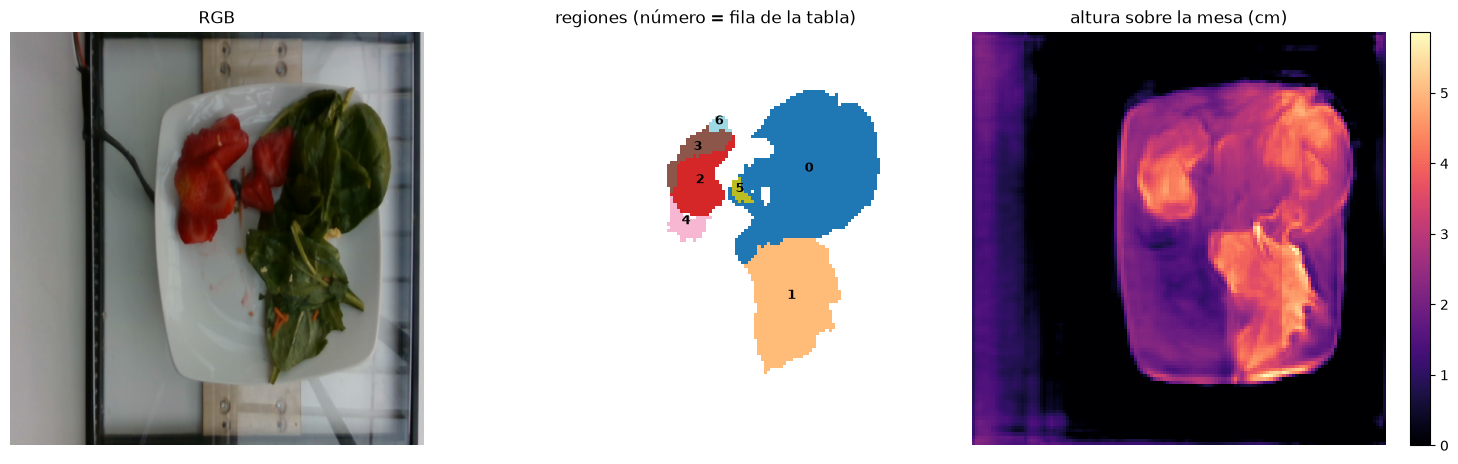

predicho: {'mass': 134.6999969482422, 'kcal': 107.69999694824219, 'fat': 5.099999904632568, 'carb': 12.199999809265137, 'protein': 4.699999809265137}
real    : {'mass': 96.0, 'kcal': 75.4, 'fat': 5.7, 'carb': 6.5, 'protein': 0.8}


,region,clase,prob_clase,area_pct,altura_cm,gramos,kcal,grasa_g,carb_g,prot_g
0,0,clase_94,0.49,9.6,3.31,60.3,46.8,2.5,3.3,1.8
1,1,clase_89,0.73,5.2,3.89,5.5,7.1,0.6,0.3,0.1
2,2,clase_30,0.22,1.6,4.00,24.5,19.7,0.7,3.4,1.0
3,3,clase_45,0.13,0.8,3.32,15.1,12.9,0.5,1.9,0.7
4,4,clase_94,0.20,0.5,2.08,17.9,13.4,0.5,1.9,0.7
5,5,clase_73,0.29,0.2,2.33,5.0,3.0,0.1,0.5,0.1
6,6,clase_73,0.15,0.2,2.86,6.5,4.9,0.2,0.8,0.3


In [ ]:
@torch.no_grad()
def predict_dish(dish_dir, model, seg, norm, depth_model=None, show=True):
    dish_dir = Path(dish_dir)
    rgb = np.array(Image.open(dish_dir / "rgb.png").convert("RGB").resize((SEG_INPUT, SEG_INPUT), Image.BILINEAR))[None]
    probs = seg.probs(rgb).cpu().numpy()[0]
    depth = get_depth_batch([dish_dir], rgb, depth_model)[0]
    P, G, M, GL, ex = build_regions(probs, depth, return_extra=True)

    Pn, Gn, Mn, GLn = apply_norm(P[None], G[None], M[None], GL[None], norm)
    t = lambda a: torch.from_numpy(a).to(DEVICE)
    model.eval()
    out = model(t(Pn), t(Gn), t(GLn), t(Mn))
    grams = out["grams"][0].cpu().numpy(); dens = out["dens"][0].cpu().numpy()
    total = out["total"][0].cpu().numpy()

    rows = []
    for r in range(int(M.sum())):
        p = P[r].copy(); p[BG_ID] = 0
        c = int(p.argmax())
        rows.append(dict(region=r, clase=seg.id2label[c], prob_clase=round(float(p[c] / max(P[r].sum(), 1e-9)), 2),
                         area_pct=round(float(G[r, 0] * 100), 1), altura_cm=round(float(G[r, 1]), 2),
                         gramos=round(float(grams[r]), 1), kcal=round(float(grams[r] * dens[r, 0]), 1),
                         grasa_g=round(float(grams[r] * dens[r, 1]), 1), carb_g=round(float(grams[r] * dens[r, 2]), 1),
                         prot_g=round(float(grams[r] * dens[r, 3]), 1)))
    table = pd.DataFrame(rows)
    totals = {t: float(round(v, 1)) for t, v in zip(TARGETS, total)}

    if show:
        fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
        ax[0].imshow(rgb[0]); ax[0].set_title("RGB"); ax[0].axis("off")
        lab = np.zeros((S, S), int)
        for r, m in enumerate(ex["masks"]): lab[m] = r + 1
        ax[1].imshow(np.ma.masked_equal(lab, 0), cmap="tab20", interpolation="nearest")
        for r, m in enumerate(ex["masks"]):
            yy, xx = np.nonzero(m); ax[1].text(xx.mean(), yy.mean(), str(r), color="k", ha="center", fontsize=9, weight="bold")
        ax[1].set_title("regiones (número = fila de la tabla)"); ax[1].axis("off")
        im = ax[2].imshow(ex["height_cm"], cmap="magma"); ax[2].set_title("altura sobre la mesa (cm)"); ax[2].axis("off")
        plt.colorbar(im, ax=ax[2], fraction=0.046); plt.tight_layout(); plt.show()
    return table, totals

dish_test = cache["ids"][sp["test"][0]]
table, totals = predict_dish(img_root / dish_test, best_model, seg, norm, depth_model)
real = {t: float(round(v, 1)) for t, v in zip(TARGETS, df.set_index("dish_id").loc[dish_test, TARGETS])}
print("predicho:", totals); print("real    :", real)
table

## 10. Guardar para integrar y para que Majo lo cargue

El checkpoint incluye los pesos, la normalización (indispensable: sin `norm` la cabeza recibe features en otra escala y falla en silencio), el prior de densidades, el `id2label` y la configuración geométrica.

In [ ]:
ckpt = dict(state=best_model.state_dict(), norm=norm, cfg=CFG, id2label=seg.id2label, n_classes=C,
            geometry=dict(S=S, SEG_INPUT=SEG_INPUT, MIN_PX=MIN_PX, R_MAX=R_MAX, BG_ID=BG_ID, DEPTH_UNIT=DEPTH_UNIT, DEPTH_MODE=DEPTH_MODE),
            use_depth=True, targets=TARGETS)
path = CACHE_DIR / f"nutrition_head_{DEPTH_MODE}.pt"
torch.save(ckpt, path)
print("guardado:", path)

def load_head(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = NutritionHead(ck["n_classes"], ck["norm"]["prior"], ck["cfg"]["hidden"], ck["cfg"]["emb"], ck["cfg"]["drop"], ck["use_depth"]).to(DEVICE)
    m.load_state_dict(ck["state"]); return m.eval(), ck["norm"], ck

guardado: head_cache\nutrition_head_model.pt


## 11. Limitaciones y qué sigue (honesto)

1. **Con `DEPTH_MODE = "gt"` los números son optimistas.** Usan la profundidad real; en la app final la profundidad será *predicha* y tendrá error. Hay que repetir el notebook con `DEPTH_MODE = "model"` y esa es la cifra que cuenta. Ideal: entrenar la cabeza con la profundidad predicha (no la real) para que aprenda a convivir con su error.
   **Ojo con el split:** el DPT se fine-tuneó con parte de Nutrition5k; en esos platos su profundidad es mejor que en fotos nuevas. Para que el test de la cabeza sea honesto, los platos de test de la cabeza deberían ser platos que el DPT **no vio** en su entrenamiento (usar el mismo split del notebook de profundidad).
2. **Cambio de dominio de la segmentación.** El SegFormer-B1 se entrenó con FoodSeg103 (mIoU ≈ 0.27) y aquí se aplica a fotos cenitales de cafetería de Nutrition5k. Si la clase sale mal, la densidad aprendida compensa parcialmente, pero el techo lo pone la segmentación. Aquí es donde entra el autoetiquetado de Nutrition5k y el fine-tuning: esta cabeza se beneficiará directamente sin cambiar una línea (solo se regenera el caché).
3. **Tu cabeza de clasificación por región** (la que subió accuracy 0.611 → 0.641 y el mIoU 0.265 → 0.321) no está enchufada por defecto: usa `seg_post` en `extract_cache` para hacerlo y comparar con/sin.
4. **La densidad nutricional aprendida es un sustituto.** Es útil para entrenar solo con etiquetas por plato, pero el objetivo final sigue siendo gramos × tabla nutricional real (propia o API). La salida `grams` por región ya está pensada para eso.
5. **Gramos por región no están validados individualmente**, solo su suma contra el total del plato (no existe ground truth por región). Por eso conviene revisar a ojo la tabla de `predict_dish` en unos cuantos platos.
6. **Split aleatorio, no oficial.** Los resultados no son comparables 1:1 con el paper de Nutrition5k hasta usar sus splits.
7. **Unidades de profundidad** (`DEPTH_UNIT`) verificadas solo con la comprobación de la sección 2; si esa comprobación sale rara, todo lo que dependa de altura/volumen estará mal escalado.

### Siguiente avance sugerido
- Correr con `DEPTH_MODE = "model"` y repetir (cifra que cuenta).
- Regenerar el caché con la segmentación fine-tuneada con Nutrition5k autoetiquetado.
- Probar `seg_post` con la cabeza de clasificación.
- Sustituir la densidad aprendida por la tabla nutricional real y reportar el error solo en gramos.